In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%pip -q install -U ultralytics pyyaml pandas matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 76.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 98.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is i

In [3]:
import os
import gc
import json
import shutil
import random
import platform
from pathlib import Path

import yaml
import torch
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. In Colab, select "
        "Runtime > Change runtime type > T4 GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(
        torch.cuda.get_device_properties(0).total_memory
        / 1024**3, 2
    ),
    "GB"
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.15
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [4]:
SOURCE_ROOT = Path("/content/drive/MyDrive/cardd_yolo")
SOURCE_YAML = SOURCE_ROOT / "dataset.yaml"

# All training data will be copied to the temporary local VM disk.
LOCAL_ROOT = Path("/content/cardd_yolo_local")
LOCAL_YAML = LOCAL_ROOT / "dataset.yaml"

# New directory: this does not overwrite the earlier experiment.
OUTPUT_ROOT = Path("/content/drive/MyDrive/Phase_04_Optimized_Training")
RUN_NAME = "yolo26m_896_musgd_cardd_v2"
RUN_DIR = OUTPUT_ROOT / RUN_NAME

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not SOURCE_YAML.exists():
    raise FileNotFoundError(
        f"Dataset YAML not found: {SOURCE_YAML}"
    )

print("Source dataset:", SOURCE_ROOT)
print("Local dataset:", LOCAL_ROOT)
print("Output directory:", RUN_DIR)


Source dataset: /content/drive/MyDrive/cardd_yolo
Local dataset: /content/cardd_yolo_local
Output directory: /content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2


In [5]:
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

for folder_name in ["images", "labels"]:
    src = SOURCE_ROOT / folder_name
    dst = LOCAL_ROOT / folder_name

    if not src.exists():
        raise FileNotFoundError(
            f"Expected folder not found: {src}"
        )

    shutil.copytree(
        src,
        dst,
        dirs_exist_ok=True,
        ignore=shutil.ignore_patterns("*.cache")
    )

shutil.copy2(SOURCE_YAML, LOCAL_YAML)

print("Dataset copied to local storage.")

Dataset copied to local storage.


In [6]:
with open(LOCAL_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

if not isinstance(data_cfg, dict):
    raise ValueError("dataset.yaml must contain a YAML mapping.")

# The copied dataset is now the root for relative paths.
data_cfg["path"] = str(LOCAL_ROOT)

def make_local_split_path(split_value):
    """
    Convert a split path from dataset.yaml into a path
    relative to LOCAL_ROOT when possible.
    """
    if split_value is None:
        return None

    values = (
        split_value if isinstance(split_value, list)
        else [split_value]
    )

    converted = []

    for value in values:
        p = Path(str(value))

        # Absolute path under the original dataset directory:
        # preserve its relative location in the local copy.
        try:
            relative = p.resolve().relative_to(
                SOURCE_ROOT.resolve()
            )
            converted.append(relative.as_posix())
            continue
        except (ValueError, OSError):
            pass

        # Normal relative paths such as images/train.
        if not p.is_absolute():
            converted.append(p.as_posix())
            continue

        # Handle absolute paths pointing to the original
        # dataset's images or labels folders.
        path_text = str(p).replace("\\", "/")
        source_text = str(SOURCE_ROOT).replace("\\", "/")

        if path_text.startswith(source_text + "/"):
            converted.append(
                path_text[len(source_text) + 1:]
            )
        else:
            raise ValueError(
                f"Cannot map dataset path locally: {value}\n"
                "Please inspect dataset.yaml and update its split paths."
            )

    return converted if isinstance(split_value, list) else converted[0]


for split in ["train", "val", "test"]:
    if split in data_cfg:
        data_cfg[split] = make_local_split_path(data_cfg[split])

with open(LOCAL_YAML, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print("\nLocal dataset configuration:")
print(LOCAL_YAML.read_text())



Local dataset configuration:
names:
  0: dent
  1: scratch
  2: crack
  3: glass shatter
  4: lamp broken
  5: tire flat
path: /content/cardd_yolo_local
test: images/test
train: images/train
val: images/val



In [7]:
import yaml
from pathlib import Path

# Safely load data_cfg if the previous cell was not executed or runtime was reset
if 'data_cfg' not in locals() and 'data_cfg' not in globals():
    LOCAL_YAML = Path("/content/cardd_yolo_local/dataset.yaml")
    LOCAL_ROOT = Path("/content/cardd_yolo_local")
    if LOCAL_YAML.exists():
        with open(LOCAL_YAML, "r") as f:
            data_cfg = yaml.safe_load(f)
    else:
        raise FileNotFoundError("dataset.yaml not found. Please run the setup cells first.")

names = data_cfg.get("names")

if isinstance(names, dict):
    class_names = [
        str(names[k]) for k in sorted(names, key=lambda x: int(x))
    ]
elif isinstance(names, list):
    class_names = [str(n) for n in names]
else:
    raise ValueError(
        "dataset.yaml must define class names using 'names'."
    )

nc = data_cfg.get("nc", len(class_names))

if int(nc) != len(class_names):
    raise ValueError(
        f"Class count mismatch: nc={nc}, names={len(class_names)}"
    )

if len(class_names) != 6:
    raise ValueError(
        f"Expected 6 CarDD classes, found {len(class_names)}: "
        f"{class_names}"
    )

for split in ["train", "val", "test"]:
    if split not in data_cfg:
        raise ValueError(
            f"'{split}' split is missing from dataset.yaml."
        )

    split_values = (
        data_cfg[split]
        if isinstance(data_cfg[split], list)
        else [data_cfg[split]]
    )

    for split_value in split_values:
        split_path = Path(split_value)

        if not split_path.is_absolute():
            split_path = LOCAL_ROOT / split_path

        if not split_path.exists():
            raise FileNotFoundError(
                f"{split} images not found: {split_path}"
            )

print("Classes:", class_names)
print("Number of classes:", nc)
print("Dataset paths validated.")

Classes: ['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']
Number of classes: 6
Dataset paths validated.


In [8]:
def count_yolo_labels(split):
    label_dir = LOCAL_ROOT / "labels" / split

    if not label_dir.exists():
        raise FileNotFoundError(
            f"YOLO label directory not found: {label_dir}"
        )

    counts = {name: 0 for name in class_names}
    total_boxes = 0
    empty_files = 0
    malformed_lines = 0

    for label_file in label_dir.glob("*.txt"):
        text = label_file.read_text().strip()

        if not text:
            empty_files += 1
            continue

        for line in text.splitlines():
            parts = line.split()

            if len(parts) != 5:
                malformed_lines += 1
                continue

            try:
                cls_id = int(float(parts[0]))
                coords = [float(v) for v in parts[1:]]
            except ValueError:
                malformed_lines += 1
                continue

            if cls_id < 0 or cls_id >= len(class_names):
                malformed_lines += 1
                continue

            if not all(0 <= v <= 1 for v in coords):
                malformed_lines += 1
                continue

            counts[class_names[cls_id]] += 1
            total_boxes += 1

    return {
        "split": split,
        "label_files": len(list(label_dir.glob("*.txt"))),
        "total_boxes": total_boxes,
        "empty_label_files": empty_files,
        "malformed_lines": malformed_lines,
        "class_counts": counts,
    }


distribution = [
    count_yolo_labels(split)
    for split in ["train", "val", "test"]
]

for item in distribution:
    print(f"\n{item['split'].upper()}")
    print("Label files:", item["label_files"])
    print("Boxes:", item["total_boxes"])
    print("Empty labels:", item["empty_label_files"])
    print("Malformed lines:", item["malformed_lines"])
    print("Class counts:", item["class_counts"])

    if item["malformed_lines"] > 0:
        raise ValueError(
            f"Invalid annotations detected in {item['split']}."
        )

with open(OUTPUT_ROOT / "annotation_audit.json", "w") as f:
    json.dump(distribution, f, indent=2)



TRAIN
Label files: 1977
Boxes: 4336
Empty labels: 0
Malformed lines: 0
Class counts: {'dent': 1270, 'scratch': 1774, 'crack': 454, 'glass shatter': 333, 'lamp broken': 347, 'tire flat': 158}

VAL
Label files: 416
Boxes: 947
Empty labels: 0
Malformed lines: 0
Class counts: {'dent': 265, 'scratch': 401, 'crack': 102, 'glass shatter': 72, 'lamp broken': 74, 'tire flat': 33}

TEST
Label files: 423
Boxes: 928
Empty labels: 0
Malformed lines: 0
Class counts: {'dent': 271, 'scratch': 385, 'crack': 95, 'glass shatter': 70, 'lamp broken': 73, 'tire flat': 34}


In [9]:
CONFIG = {
    # Model and dataset
    "model": "yolo26m.pt",
    "data": str(LOCAL_YAML),

    # Training duration
    "epochs": 220,
    "patience": 45,

    # Higher resolution for small damage regions
    "imgsz": 896,

    # Conservative fixed batch for a 16 GB-class T4
    "batch": 4,
    "device": 0,
    "workers": 2,

    # Pretrained fine-tuning
    "pretrained": True,
    "freeze": None,

    # Optimizer and learning-rate schedule
    "optimizer": "MuSGD",
    "lr0": 0.002,
    "lrf": 0.01,
    "momentum": 0.937,
    "weight_decay": 0.0005,
    "warmup_epochs": 3.0,
    "warmup_momentum": 0.8,
    "warmup_bias_lr": 0.05,
    "cos_lr": True,

    # Detection loss weights
    "box": 7.5,
    "cls": 0.5,
    "dfl": 1.5,
    "cls_pw": 0.25,

    # Geometric augmentation
    "degrees": 2.0,
    "translate": 0.08,
    "scale": 0.35,
    "shear": 0.0,
    "perspective": 0.0,
    "fliplr": 0.5,
    "flipud": 0.0,

    # Color augmentation
    "hsv_h": 0.01,
    "hsv_s": 0.35,
    "hsv_v": 0.20,

    # Composition augmentation
    "mosaic": 0.70,
    "mixup": 0.0,
    "close_mosaic": 20,
    "copy_paste": 0.0,

    # Generalization and reproducibility
    "multi_scale": 0.0,
    "rect": False,
    "seed": SEED,
    "deterministic": True,
    "amp": True,

    # Training output
    "project": str(OUTPUT_ROOT),
    "name": RUN_NAME,
    "exist_ok": False,
    "save": True,
    "save_period": 20,
    "plots": True,
    "val": True,
    "verbose": True,
    "cache": "disk",
    "resume": False,
}

# Save the exact configuration used for this run.
with open(OUTPUT_ROOT / "training_config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print(json.dumps(CONFIG, indent=2))


{
  "model": "yolo26m.pt",
  "data": "/content/cardd_yolo_local/dataset.yaml",
  "epochs": 220,
  "patience": 45,
  "imgsz": 896,
  "batch": 4,
  "device": 0,
  "workers": 2,
  "pretrained": true,
  "freeze": null,
  "optimizer": "MuSGD",
  "lr0": 0.002,
  "lrf": 0.01,
  "momentum": 0.937,
  "weight_decay": 0.0005,
  "warmup_epochs": 3.0,
  "warmup_momentum": 0.8,
  "warmup_bias_lr": 0.05,
  "cos_lr": true,
  "box": 7.5,
  "cls": 0.5,
  "dfl": 1.5,
  "cls_pw": 0.25,
  "degrees": 2.0,
  "translate": 0.08,
  "scale": 0.35,
  "shear": 0.0,
  "perspective": 0.0,
  "fliplr": 0.5,
  "flipud": 0.0,
  "hsv_h": 0.01,
  "hsv_s": 0.35,
  "hsv_v": 0.2,
  "mosaic": 0.7,
  "mixup": 0.0,
  "close_mosaic": 20,
  "copy_paste": 0.0,
  "multi_scale": 0.0,
  "rect": false,
  "seed": 42,
  "deterministic": true,
  "amp": true,
  "project": "/content/drive/MyDrive/Phase_04_Optimized_Training",
  "name": "yolo26m_896_musgd_cardd_v2",
  "exist_ok": false,
  "save": true,
  "save_period": 20,
  "plots": true,


In [ ]:
gc.collect()
torch.cuda.empty_cache()

model = YOLO(CONFIG["model"])

train_results = model.train(**CONFIG)

print("\nTraining call completed.")
print("Expected run directory:", RUN_DIR)



Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.25, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/cardd_yolo_local/dataset.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=220, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.35, hsv_v=0.2, imgsz=896, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m.pt, momentum=0.937, mosaic=0.7, multi_scale=0.0, name=yolo26m_896_musgd_cardd_v2, nbs=64, nms=None, opse

In [ ]:
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_WEIGHTS}\n"
        "Check the actual save_dir printed by Ultralytics."
    )

print("Best checkpoint:", BEST_WEIGHTS)
print("Best checkpoint size (MB):",
      round(BEST_WEIGHTS.stat().st_size / (1024**2), 2))

if LAST_WEIGHTS.exists():
    print("Last checkpoint:", LAST_WEIGHTS)



Best checkpoint: /content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2/weights/best.pt
Best checkpoint size (MB): 42.03
Last checkpoint: /content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2/weights/last.pt


In [ ]:
RESULTS_CSV = RUN_DIR / "results.csv"

if RESULTS_CSV.exists():
    history = pd.read_csv(RESULTS_CSV)
    history.columns = history.columns.str.strip()

    print("\nAvailable result columns:")
    print(history.columns.tolist())

    # Automatically locate the validation mAP columns.
    map50_col = next(
        (c for c in history.columns
         if "metrics/mAP50(B)" in c),
        None
    )

    map5095_col = next(
        (c for c in history.columns
         if "metrics/mAP50-95(B)" in c),
        None
    )

    if map50_col:
        idx50 = history[map50_col].idxmax()
        print(
            "Best recorded mAP50:",
            round(float(history.loc[idx50, map50_col]), 4),
            "at epoch", int(idx50) + 1
        )

    if map5095_col:
        idx95 = history[map5095_col].idxmax()
        print(
            "Best recorded mAP50-95:",
            round(float(history.loc[idx95, map5095_col]), 4),
            "at epoch", int(idx95) + 1
        )

    display(history.tail())

    history.to_csv(
        OUTPUT_ROOT / "training_history_copy.csv",
        index=False
    )
else:
    print("results.csv was not found at the expected path.")



Available result columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2', 'lr/pg3', 'lr/pg4', 'lr/pg5', 'lr/pg6', 'lr/pg7']
Best recorded mAP50: 0.7286 at epoch 46
Best recorded mAP50-95: 0.5595 at epoch 80


,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
120,121,19277.8,0.65002,0.36426,0.00785,0.79510,0.68677,0.70123,0.54643,1.36895,1.61203,0.02295,0.002607,0.000869,0.002607,0.000869,0.002607,0.000869,0.002607,0.000869
121,122,19437.1,0.64629,0.35361,0.00781,0.81148,0.69127,0.71447,0.55420,1.35030,1.53837,0.02242,0.002565,0.000855,0.002565,0.000855,0.002565,0.000855,0.002565,0.000855
122,123,19595.2,0.64187,0.35766,0.00762,0.77073,0.69981,0.70880,0.55436,1.35617,1.57987,0.02260,0.002524,0.000841,0.002524,0.000841,0.002524,0.000841,0.002524,0.000841
123,124,19753.8,0.64971,0.36502,0.00785,0.77783,0.70630,0.70298,0.54396,1.38794,1.57024,0.02314,0.002482,0.000827,0.002482,0.000827,0.002482,0.000827,0.002482,0.000827
124,125,19911.7,0.64537,0.35065,0.00777,0.76966,0.71738,0.70659,0.54595,1.37679,1.57746,0.02323,0.002440,0.000813,0.002440,0.000813,0.002440,0.000813,0.002440,0.000813


In [ ]:
best_model = YOLO(str(BEST_WEIGHTS))

val_metrics = best_model.val(
    data=str(LOCAL_YAML),
    split="val",
    imgsz=896,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    save_json=True,
    project=str(OUTPUT_ROOT),
    name="final_validation",
    exist_ok=True,
)

validation_summary = {
    "checkpoint": str(BEST_WEIGHTS),
    "split": "val",
    "precision": float(val_metrics.box.mp),
    "recall": float(val_metrics.box.mr),
    "mAP50": float(val_metrics.box.map50),
    "mAP50_95": float(val_metrics.box.map),
}

with open(OUTPUT_ROOT / "validation_metrics.json", "w") as f:
    json.dump(validation_summary, f, indent=2)

print("\nFINAL VALIDATION")
print(json.dumps(validation_summary, indent=2))


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,354,078 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 138.6±29.2 MB/s, size: 893.2 KB)
val: Scanning /content/cardd_yolo_local/labels/val.cache... 416 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 416/416 91.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 104/104 4.1it/s 25.1s
                   all        416        947      0.794      0.704      0.718      0.557
                  dent        186        265      0.751      0.491      0.527      0.313
               scratch        226        401      0.592      0.491      0.469      0.266
                 crack         65        102      0.674      0.465      0.487      0.276
         glass shatter         71         72      0.975      0.972      0.991      0.888
           lamp broken         74 

In [ ]:
test_metrics = best_model.val(
    data=str(LOCAL_YAML),
    split="test",
    imgsz=896,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    save_json=True,
    project=str(OUTPUT_ROOT),
    name="final_test",
    exist_ok=True,
)

test_summary = {
    "checkpoint": str(BEST_WEIGHTS),
    "split": "test",
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50_95": float(test_metrics.box.map),
}

with open(OUTPUT_ROOT / "test_metrics.json", "w") as f:
    json.dump(test_summary, f, indent=2)

print("\nFINAL HELD-OUT TEST RESULTS")
print(json.dumps(test_summary, indent=2))


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m summary (fused): 130 layers, 20,354,078 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 149.5±23.3 MB/s, size: 767.0 KB)
val: Scanning /content/cardd_yolo_local/labels/test... 423 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 423/423 459.6it/s 0.9s
val: New cache created: /content/cardd_yolo_local/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 106/106 4.2it/s 25.5s
                   all        423        928      0.753      0.717      0.721      0.559
                  dent        187        271      0.747      0.545      0.571      0.311
               scratch        226        385      0.644       0.59      0.585      0.337
                 crack         65         95      0.447      0.389       0.32      0.184
         glass shatter         70         70      0.985     

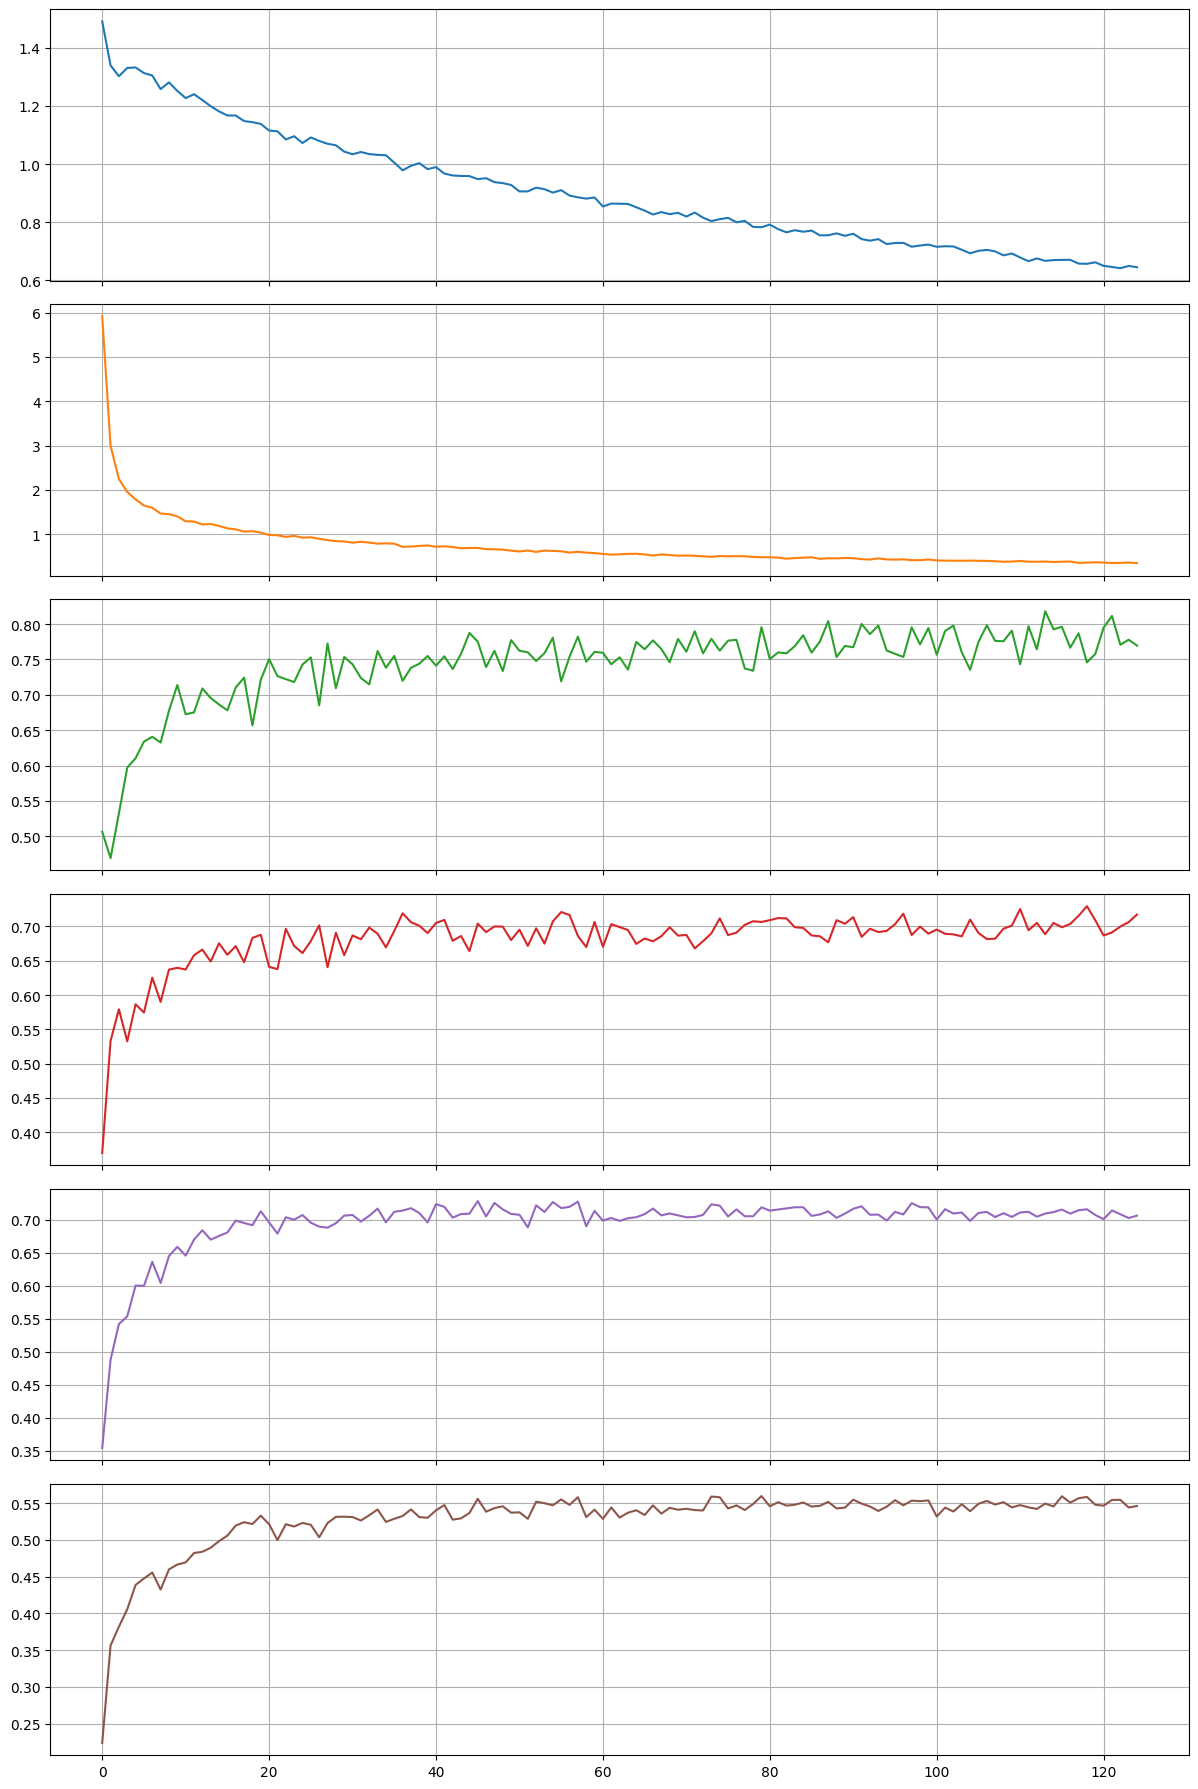


PIPELINE FINISHED
{
  "model": "YOLO26m",
  "input_resolution": 896,
  "number_of_classes": 6,
  "class_names": [
    "dent",
    "scratch",
    "crack",
    "glass shatter",
    "lamp broken",
    "tire flat"
  ],
  "best_weights": "/content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2/weights/best.pt",
  "run_directory": "/content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2",
  "training_configuration": "/content/drive/MyDrive/Phase_04_Optimized_Training/training_config.json",
  "validation_metrics": {
    "checkpoint": "/content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2/weights/best.pt",
    "split": "val",
    "precision": 0.7938561808596439,
    "recall": 0.7044913977208314,
    "mAP50": 0.718050406716344,
    "mAP50_95": 0.5571288265388287
  },
  "test_metrics": {
    "checkpoint": "/content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2/weights/best.pt",
    "split": "test",
    "p

In [ ]:
if RESULTS_CSV.exists():
    history = pd.read_csv(RESULTS_CSV)
    history.columns = history.columns.str.strip()

    columns_to_plot = [
        c for c in history.columns
        if any(term in c for term in [
            "train/box_loss",
            "train/cls_loss",
            "metrics/precision(B)",
            "metrics/recall(B)",
            "metrics/mAP50(B)",
            "metrics/mAP50-95(B)",
        ])
    ]

    if columns_to_plot:
        history[columns_to_plot].plot(
            subplots=True,
            figsize=(12, 3 * len(columns_to_plot)),
            grid=True,
            legend=False
        )
        plt.tight_layout()
        plt.savefig(
            OUTPUT_ROOT / "training_metrics.png",
            dpi=160,
            bbox_inches="tight"
        )
        plt.show()


# CELL 15 — Save a final run summary

summary = {
    "model": "YOLO26m",
    "input_resolution": 896,
    "number_of_classes": len(class_names),
    "class_names": class_names,
    "best_weights": str(BEST_WEIGHTS),
    "run_directory": str(RUN_DIR),
    "training_configuration": str(
        OUTPUT_ROOT / "training_config.json"
    ),
    "validation_metrics": validation_summary,
    "test_metrics": test_summary,
}

with open(OUTPUT_ROOT / "final_run_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nPIPELINE FINISHED")
print(json.dumps(summary, indent=2))
print("\nAll artifacts:", OUTPUT_ROOT)


**Fine Tuning**

In [10]:


import torch
from pathlib import Path
import yaml
import json
import pandas as pd
from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU.")

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GB):", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
))


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


In [11]:
OUTPUT_ROOT = Path("/content/drive/MyDrive/Phase_04_Optimized_Training")

CHECKPOINT = (
    OUTPUT_ROOT
    / "yolo26m_896_musgd_cardd_v2"
    / "weights"
    / "best.pt"
)

DATASET_ROOT = Path("/content/cardd_yolo_local")

# Find dataset YAML files that define train and val splits.
yaml_candidates = list(DATASET_ROOT.rglob("*.yaml")) + list(DATASET_ROOT.rglob("*.yml"))

valid_yaml_files = []

for candidate in yaml_candidates:
    try:
        with open(candidate, "r", encoding="utf-8") as f:
            content = yaml.safe_load(f)

        if isinstance(content, dict) and "train" in content and "val" in content:
            valid_yaml_files.append((candidate, content))
    except Exception:
        continue

if not CHECKPOINT.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT}")

if not valid_yaml_files:
    raise FileNotFoundError(
        f"No dataset YAML containing train and val was found under {DATASET_ROOT}. "
        "Set DATA_YAML manually to the YAML used in your previous training."
    )

# Prefer the YAML that defines the expected six classes.
matches = [
    (path, content) for path, content in valid_yaml_files
    if len(content.get("names", [])) == 6
]

if not matches:
    raise ValueError(
        "Could not identify a six-class dataset YAML. "
        "Inspect yaml_candidates and select the correct YAML manually."
    )

DATA_YAML, DATA_CONFIG = matches[0]

print("Checkpoint:", CHECKPOINT)
print("Dataset YAML:", DATA_YAML)
print("Dataset classes:", DATA_CONFIG["names"])
print("Output root:", OUTPUT_ROOT)

assert len(DATA_CONFIG["names"]) == 6, "Expected exactly six damage classes."


Checkpoint: /content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2/weights/best.pt
Dataset YAML: /content/cardd_yolo_local/dataset.yaml
Dataset classes: {0: 'dent', 1: 'scratch', 2: 'crack', 3: 'glass shatter', 4: 'lamp broken', 5: 'tire flat'}
Output root: /content/drive/MyDrive/Phase_04_Optimized_Training


In [12]:
RUN_NAME = "yolo26m_1024_finetune_v3"
RUN_DIR = OUTPUT_ROOT / RUN_NAME

if RUN_DIR.exists():
    raise FileExistsError(
        f"{RUN_DIR} already exists. Change RUN_NAME to avoid overwriting a run."
    )

CONFIG = {
    "model_checkpoint": str(CHECKPOINT),
    "data": str(DATA_YAML),
    "imgsz": 1024,
    "epochs": 70,
    "patience": 20,
    "batch": -1,
    "optimizer": "MuSGD",
    "lr0": 0.0003,
    "lrf": 0.1,
    "weight_decay": 0.00027,
    "warmup_epochs": 2,
    "cos_lr": True,
    "cls_pw": 0.25,
    "mosaic": 0.6,
    "close_mosaic": 10,
    "mixup": 0.0,
    "degrees": 2.0,
    "translate": 0.08,
    "scale": 0.5,
    "fliplr": 0.5,
    "flipud": 0.0,
    "hsv_h": 0.01,
    "hsv_s": 0.4,
    "hsv_v": 0.25,
    "seed": 42
}

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_ROOT / f"{RUN_NAME}_config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print(json.dumps(CONFIG, indent=2))


{
  "model_checkpoint": "/content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_896_musgd_cardd_v2/weights/best.pt",
  "data": "/content/cardd_yolo_local/dataset.yaml",
  "imgsz": 1024,
  "epochs": 70,
  "patience": 20,
  "batch": -1,
  "optimizer": "MuSGD",
  "lr0": 0.0003,
  "lrf": 0.1,
  "weight_decay": 0.00027,
  "warmup_epochs": 2,
  "cos_lr": true,
  "cls_pw": 0.25,
  "mosaic": 0.6,
  "close_mosaic": 10,
  "mixup": 0.0,
  "degrees": 2.0,
  "translate": 0.08,
  "scale": 0.5,
  "fliplr": 0.5,
  "flipud": 0.0,
  "hsv_h": 0.01,
  "hsv_s": 0.4,
  "hsv_v": 0.25,
  "seed": 42
}


In [13]:
previous_model = YOLO(str(CHECKPOINT))

print("Checkpoint model:", previous_model.ckpt.get("train_args", {}).get("model"))
print("\nPrevious training arguments:")

for key, value in sorted(
    previous_model.ckpt.get("train_args", {}).items()
):
    print(f"{key}: {value}")

del previous_model


Checkpoint model: yolo26m.pt

Previous training arguments:
agnostic_nms: False
amp: True
angle: 1.0
augment: False
auto_augment: randaugment
batch: 4
bgr: 0.0
box: 7.5
cache: disk
cfg: None
channels_last: None
classes: None
close_mosaic: 20
cls: 0.5
cls_pw: 0.25
cls_remap: True
compile: False
conf: None
copy_paste: 0.0
copy_paste_mode: flip
cos_lr: True
cutmix: 0.0
data: /content/cardd_yolo_local/dataset.yaml
degrees: 2.0
deterministic: True
device: 0
dfl: 1.5
dgrad: 0.5
dis: 6.0
distill_model: None
dlam: 1.0
dlog: 1.0
dnn: False
dropout: 0.0
dynamic: False
embed: None
epochs: 220
erasing: 0.4
exist_ok: False
fliplr: 0.5
flipud: 0.0
format: torchscript
fraction: 1.0
freeze: None
hsv_h: 0.01
hsv_s: 0.35
hsv_v: 0.2
imgsz: 896
iou: 0.7
kobj: 1.0
line_width: None
lr0: 0.002
lrf: 0.01
mask_ratio: 4
max_det: 300
mixup: 0.0
mode: train
model: yolo26m.pt
momentum: 0.937
mosaic: 0.7
multi_scale: 0.0
name: yolo26m_896_musgd_cardd_v2
nbs: 64
nms: None
opset: None
optimize: False
optimizer: MuSGD


In [ ]:

torch.cuda.empty_cache()

model = YOLO(str(CHECKPOINT))

train_results = model.train(
    data=str(DATA_YAML),

    # Higher resolution to investigate small-damage detection.
    imgsz=1024,

    # Fine-tuning schedule.
    epochs=70,
    patience=20,
    batch=-1,
    device=0,
    workers=4,

    # Explicit optimization settings.
    optimizer="MuSGD",
    lr0=0.0003,
    lrf=0.1,
    weight_decay=0.00027,
    warmup_epochs=2,
    cos_lr=True,

    # Class imbalance and augmentations.
    cls_pw=0.25,
    mosaic=0.6,
    close_mosaic=10,
    mixup=0.0,
    degrees=2.0,
    translate=0.08,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    hsv_h=0.01,
    hsv_s=0.4,
    hsv_v=0.25,

    # Reproducibility and checkpointing.
    seed=42,
    deterministic=True,
    pretrained=True,
    amp=True,
    save=True,
    save_period=10,
    plots=True,
    val=True,

    # Keep this experiment separate from previous runs.
    project=str(OUTPUT_ROOT),
    name=RUN_NAME,
    exist_ok=False,
    resume=False
)

print("\nFine-tuning finished.")
print("Run directory:", RUN_DIR)
print("Best checkpoint:", RUN_DIR / "weights" / "best.pt")

In [ ]:


BEST_CHECKPOINT = RUN_DIR / "weights" / "best.pt"

if not BEST_CHECKPOINT.exists():
    raise FileNotFoundError(f"Best checkpoint not found: {BEST_CHECKPOINT}")

best_model = YOLO(str(BEST_CHECKPOINT))

validation_results = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=1024,
    batch=4,
    device=0,
    plots=True,
    save_json=True,
    project=str(OUTPUT_ROOT),
    name=f"{RUN_NAME}_validation",
    exist_ok=True
)

# Ultralytics detection metrics.
box_metrics = validation_results.box

summary = {
    "checkpoint": str(BEST_CHECKPOINT),
    "split": "val",
    "imgsz": 1024,
    "precision": float(box_metrics.mp),
    "recall": float(box_metrics.mr),
    "mAP50": float(box_metrics.map50),
    "mAP50_95": float(box_metrics.map),
    "per_class_mAP50_95": {
        str(name): float(score)
        for name, score in zip(
            DATA_CONFIG["names"],
            box_metrics.maps
        )
    }
}

summary_path = OUTPUT_ROOT / f"{RUN_NAME}_validation_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nFINE-TUNED VALIDATION SUMMARY")
print(json.dumps(summary, indent=2))




In [16]:
baseline = {
    "model": "YOLO26m baseline (896)",
    "precision": 0.7938561808596439,
    "recall": 0.7044913977208314,
    "mAP50": 0.718050406716344,
    "mAP50_95": 0.5571288265388287
}

comparison = pd.DataFrame([
    baseline,
    {
        "model": "YOLO26m fine-tuned (1024)",
        "precision": summary["precision"],
        "recall": summary["recall"],
        "mAP50": summary["mAP50"],
        "mAP50_95": summary["mAP50_95"]
    }
])

metric_columns = ["precision", "recall", "mAP50", "mAP50_95"]

print(comparison.to_string(index=False))

print("\nAbsolute change vs baseline (percentage points):")

for metric in metric_columns:
    delta = (
        summary[metric] - baseline[metric]
    ) * 100

    print(f"{metric}: {delta:+.2f} pp")

comparison.to_csv(
    OUTPUT_ROOT / f"{RUN_NAME}_comparison.csv",
    index=False
)

print("\nSaved summary:", summary_path)
print("Saved comparison:", OUTPUT_ROOT / f"{RUN_NAME}_comparison.csv")


                    model  precision   recall    mAP50  mAP50_95
   YOLO26m baseline (896)   0.793856 0.704491 0.718050  0.557129
YOLO26m fine-tuned (1024)   0.822316 0.699232 0.725608  0.553570

Absolute change vs baseline (percentage points):
precision: +2.85 pp
recall: -0.53 pp
mAP50: +0.76 pp
mAP50_95: -0.36 pp

Saved summary: /content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_1024_finetune_v3_validation_summary.json
Saved comparison: /content/drive/MyDrive/Phase_04_Optimized_Training/yolo26m_1024_finetune_v3_comparison.csv
